# fila zero · Data Science com dados reais
## Proximidade geográfica entre UBS e pronto atendimento em São Paulo

**Integrantes:** Lucas Cavalcante (RM 562857); Matheus Rodrigues (RM 561689);
Caio Nascimento Batista (RM 561383); Manoah Leão (RM 563713).  
**Disciplina:** Data Science & Statistical Computing · Global Solution 2026.2 · FIAP.  
**Data do estudo:** 17/11/2026.

**Pergunta de decisão:** como os dados públicos de cadastro podem orientar a expansão e a
curadoria do catálogo do FilaZero, considerando a proximidade geográfica entre serviços?

Este trabalho usa registros reais do CNES e a malha municipal do IBGE para estudar
qualidade cadastral e proximidade entre estabelecimentos. As distâncias são variáveis
calculadas a partir das coordenadas, com método e critérios de seleção explícitos.

## 1. Problema, contexto e recorte

O FilaZero apresenta unidades de saúde em um mapa para facilitar sua localização e
consulta. O Documento de Visão contextualiza a orientação ao cidadão e a comparação
entre unidades; o guia visual define uma comunicação clara sobre a origem dos dados.

Um catálogo útil precisa identificar corretamente os estabelecimentos, seus tipos e
suas coordenadas. Diferenças de classificação e posições cadastrais suspeitas podem
alterar a leitura do mapa e das distâncias. Esse é o problema investigado neste estudo.

O trabalho avalia um extrato oficial do CNES, identifica registros para revisão e
descreve a proximidade entre UBS e pronto atendimento em São Paulo. A análise espacial
e a avaliação de qualidade cadastral constituem o objetivo completo deste trabalho e
apoiam a organização e a expansão do catálogo do FilaZero.

**Unidade de análise:** estabelecimento com código CNES. **Alvo geográfico:** município
de São Paulo. O resultado usa UBS como pontos de referência existentes; elas não são
endereços de pacientes, amostra da população ou origem de uma recomendação clínica.

## 2. Como reproduzir

Abra no Jupyter ou Google Colab e execute as células em ordem. A base real está
incorporada neste notebook, com origem, consultas e SHA-256, para permitir a entrega
de apenas dois arquivos. A execução padrão funciona sem internet depois de instalar
as bibliotecas. Não precisa clonar o projeto nem baixar um CSV separado.

Dependências usadas: Python 3.12, NumPy, pandas, Matplotlib e IPython.
Se necessário, execute em uma célula: `%pip install numpy pandas matplotlib`.
As versões efetivamente executadas aparecem abaixo. A análise combina preparação de
dados, validação geográfica, vizinhos mais próximos, estatística descritiva e análise
de sensibilidade para apoiar a curadoria do catálogo.

In [1]:
import base64, gzip, hashlib, json, math, os, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.path import Path as GeoPath
from IPython.display import display, Markdown

pd.set_option('display.max_colwidth', 65)
pd.set_option('display.max_columns', 10)
AZUL, TINTA, CINZA = '#0A3CFF', '#0B0B0D', '#737680'
plt.rcParams.update({'font.family':'DejaVu Sans', 'font.size':10,
                     'axes.spines.top':False, 'axes.spines.right':False,
                     'axes.titleweight':'bold', 'figure.dpi':120})
FIGURAS = {}
def exibir_figura(nome, fig):
    # Salvar é opcional e só é usado na preparação do relatório em PDF.
    FIGURAS[nome] = fig
    pasta = os.environ.get('FILA_ZERO_ARTEFATOS')
    if pasta:
        Path(pasta).mkdir(parents=True, exist_ok=True)
        fig.savefig(Path(pasta)/(nome+'.png'), dpi=190, bbox_inches='tight')
    plt.show()
    plt.close(fig)

print('Python:', platform.python_version())
print('NumPy:', np.__version__, '| pandas:', pd.__version__, '| Matplotlib:', matplotlib.__version__)

Python: 3.12.14
NumPy: 2.5.5 | pandas: 3.0.1 | Matplotlib: 3.11.2


## 3. Fontes e proveniência

1. **Ministério da Saúde / CNES:** [catálogo oficial](https://dadosabertos.saude.gov.br/dataset/cnes-cadastro-nacional-de-estabelecimentos-de-saude),
   [API](https://apidadosabertos.saude.gov.br/v1/). Coleta em 17/11/2026.
   Município CNES **355030**; tipos **02** (Centro de Saúde/Unidade Básica),
   **73** (Pronto Atendimento), **05** (Hospital Geral), **07** (Hospital Especializado);
   filtro solicitado `status=1`. A API retornou páginas de até 20 registros;
   `offset` foi incrementado como índice de página. O manifesto guarda cada URL e o hash
   do corpo original. Validamos tipo, município e ausência de IDs repetidos entre páginas.
2. **IBGE:** [malha municipal](https://www.ibge.gov.br/geociencias/organizacao-do-territorio/malhas-territoriais/15774-malhas.html),
   [consulta GeoJSON](https://servicodados.ibge.gov.br/api/v3/malhas/municipios/3550308?formato=application/vnd.geo%2Bjson&qualidade=maxima).
   O código IBGE **3550308** inclui o dígito adicional em relação ao CNES. A malha da API
   é simplificada, mesmo com qualidade máxima. Não atribuímos a ela ano de referência
   que não foi informado na resposta; a data de acesso é 17/11/2026.
3. **Contexto do projeto:** [FilaZero, commit 4008bc6](https://github.com/Luqetaa/FilaZero/tree/4008bc625ce49e4927f6a81783441b55c9121e4d),
   Documento de Visão e Guia de Identidade Visual. O guia orienta a paleta azul, fundo
   claro, tipografia e a distinção entre dado observado, derivado e indisponível.

O extrato incorporado preserva os valores de 12 campos do cadastro e remove contatos,
CNPJs e campos que não entram na análise. Não se corrigem coordenadas manualmente.
Hash do extrato CNES descompactado: `278fd0a1fd58d24ad93cb2e21a1e22e1fad38d762678cae4d8f85b376d282b95`.
Hash do GeoJSON IBGE: `f1bdf75deb96e3f7a990387b2e74cde752ddb8e87eebe448de006e36926bb718`.

In [2]:
# Cópias reais incorporadas; base64/gzip é somente compactação, não geração de dados.
CNES_B64 = '...'
IBGE_B64 = 'H4sIAAAAAAACCm2dy85dN46FXyXwOBVsXShSNW2gxz0PMghS7kKA6nLgdg+CIO/eOom5+J3sPTOWdbQlindS+n/78OXXXz5++Ps3H/7z449f/u/zx//49K9/ffzpy8+f/v3h228+/Pef4P+eAd//9tehrwH//Pjpfz5++fzrgev//+vTv379558T/PTp0+d//PzvH7/8Ocf33/9tru9Wa/vbb/7Wx3d7efzw7TeJrkSXFXrNRG0LvaInOlah2xO9BsbGV5QTrPyYOYb6SBRLADoc6BaK5baWaGtYWC53RmCGEGpPqHFszjtnPGxttvGwsnmthxlGYBeRexvesd4Qiq1NgUXIpt9HA6jfLww1TbBw7EuoDaC5h4EDxljsrE2hbWK5OUPfT0zWQcadE3THfq/kpj5B3J1k7H0/oeC8diXaNoiTGM8xP9XemDyEYgMaOufDts6qC+05wRX+MMPl3EEe5DVB2iHUsIaZ7HyByZvlWEBfPxUb3CU+iG3kgwQnQUu040ue0wbEqUWChm95Thsk18oJnLyREhLOaS1n8IWjzQnWtofVLmt3Vo6FdYUmwIH1nqhFrbZPoQtjd37MZi1hiArW6xhHzz1QKw3L/Q7on5HTQu7G1MiJ3ycbxGi1rpGyHx2kGT3PvIMTug6yA5w5QcMEPYU8Gg6nD6FQwn3kci9Mm8LgPIee23USPAnj0YoIc3wlotuusdNyAsPG8sScFmP6TPSqxc6v3OETjGBXfmtARKwneAFMDeyj4fdNQwudyZ/eo4R0XjlBhykcNRZqefRcQr9qhnEl2jYPN/fQIDg9VcJBQfGeX2tUCaF5u9+NgDeQMQXSLxxki5z2wtZ660LJH3kQl8072x2ULJpgB9fpW1BVfQ2hG6QRiqG1WNiQc1J/omtDW4/c7tqg4kgduvbA2FzYQftdJaxN4U3OPyhOPc9sxca8I1cGgUx7sYJKKSVnRcdqayykbCTnL+e3rtyDOxRQOlvLSdzQ2Iskz7ELyq6vSHQ9gSBYT7Y7fui6q4qDjruuWasRzRkWGLc//L6lI7toB5prrNNTGhp7d4nWevNHNEHAMdR2DXJ6jULhyHbNUD6RbfGoAUwP+6itXWiqy6O3vNAhKl5Av2KzlNUhR846Sx4t0gysMk9naE4AxxITDI7V0YySaIv0eA9PBT6Wiy0LeyZIwvTSzebpVK2rxOGgOe3Vamee3t66OIOb0NqET40te24r9DUDavpacY1ZTtDKDTXTkbWi7TnoBHE2JuEtGTNLj/nwVC1gipkvK4LVDjh01dD61qyxpQJtzKQMHGGTgTpozVuKos2at+t0TrxSqA69ggnr2lkD2zURvGETzUVbELyJnc+vChUvgRPkzB9LVetSTHZ8ltrDJf3RDWPTjzxobeK6xLi137nDn1Dpmj53odoEQqJZ0ouvzd3H01gp8l5hxgyRrOzDDOklRFonUtYENWtMe9gDZLIoNn3Xaq3Q2m95h9OX5t2YQRIFP+ygUiydY5vUTe3XZRDHwhpGnsQoxpkuOo5SQnOJ5m+ojOcsz3daulFHOxYhrfRr6ZCprc0LQ+VBTJyP3NmXZ1yoFjbLB5lnNs1QCxuSHy5MtEFOY45eq639jmYPexhNin8TLerWJuS6npOohXXXDHWUXYoQnvpBtYRabZd2nERbkQYTtPFA3C5ZLTV2dl5mroY2qQCke84AExFqY0rMIG12SCcQElHOwsBBKidx0BpbLsTA6VzymJCBObQro+qYV+KHj8kedSz3slJjtbNr+IOwX2XBQdzrkmoqR2xsiUkx49heij8KtbI9o1DZqdYxbSZ8XikWfCy3dmHacgz4MXmuFz9WZr0kauwhd6Hcq5HZR/iCY4vi18DvdeilP0ZIN16lFEbp3KvEYcg5sl3BO9HABD3BhZGJlVEfkebMkAUaUu+2uayvWJTjPNyFliwcdCVaWejhW2OtP6EDO8gFxBsFTOh4QB0fi9RJVnnH861cly9/2IOXQR6ppw4IwqSeOWECKJuiYN7XA2kdbITVgj0LRcR3ZigUM2R4aYisRmQy39bbJnIXC3IjlxxRyYiloQ1LiELBygnapigkGY0ipj0YRWzk+RpFLNXPcXehJ1Iajrvbb4J3QOxBbDOdQpYHMQ3MFELHxNaSNLAD+BjFPNWiIb9/0KTCADvXHqgR0q2x8bbdJEKH8MrlO2PtrmnOWMi0JKo7pDcDACOPpuE1qPaRCtQ62UNgWw/ap1/zgUNbkENzWW3Fg0i2BaWwamzxnWfofVz+ATRpi1hjeKbMX4FAoeK7huP1DEEOWmtYS18Dj64M7w6LboxNsAzvGZrEubCwlSq/jnFltHRiA6I70QI9A5gjC9hAsuKJ50GClOjjxAPN050BuqQwTOTnSzXPN8XaEzSqwPyW044ke803JZpu6JnB7vx5xpIVNQOUSq0WnISh0EqKfyZVqCYIsPjWHuKC5GVq+IyFslui4oREb81L/+nSvAZfK03JKxqDrzU1Fm6Zpi1pKBfuDCWq5TZ8TLMirLpM57DhwaWQnUPHtKbzLZtRbugJ8rDcaBpL99bupz5VVyaHHEdWKOJTlW8nDOpUJXA6Ntwu7e2CP9819oI7rhOG+a6IYCJiLC6fCCiaVluqZqrWcmZFSLJEBcREknQfmLakzxCXDXE5ZhhD0655C/fOBA5wPJzOKBqUyj6xVHEIlrDFeJVjn7M/MJOyTm+Mp7rK4VGgXoIGVGwT5cGcaFzoQOA+HiZY4lzI+uEVjUU471MHUT7u698iORIrD1RUBmUilz5DGpe/l6MwCca+T2tXHXnltyANtVZTkwQV+TFgfleNpmrPOQbkzaAbDVm6cdd3xxWQckXOutc5GGZY0neVOjBVFOZGYlT1j0MlJCDFuajMWHHjDiQ25ZJfJf8HTUN/Vd3fJCeH0Jgh+cauahywqQmwBJM//JTGfZ1UoSZnpWTnuNHyFJyo9oA07EodZoCSAuUgW4kIqSVaYfXSPgHmWGW0AhnvJpaZRO8mx9S+cnhuYFpxrft9ArgUtkqtgrmAlpCfOGbeFbut9AHnAmss2c3Fr0mcFvLY5ZktVg5EWguiuTKD7LpMr0FwltjeSDIpCp6PVOhc3EQuF6ktbHi2JzIgoWmqjh/d/0ScgQkyr3TszNMeBpcgkzGgVLQHNC6cdQl1TFBjkbhfYpHGPWSm5qBgR/m9jZyvnTUk7pXsnQgTTB0zb6jJIDcwg8nbaSgYmXTrVVGcFaNzArkErC3JklyNv/96kq8k133WsUFHS/tyIkrUkZrQjo9dmgF7mFlKP040NGDqkEF1m0c5goWojMwGtcWcGgsqzAyWTtQB1ZxuyYCnf2bIhTnKj1NDB0pZaVBPkFcLG5n3O0EWSlnpdZ5wLmB1ZqKc1wod+FpSd6EEO1NdDBSnjy3KsagYv3IRibrdrM5AMquKf8Noi2papzHScll/FHXXiFv98sSvkJNLE1D+xGNrU1aT5FRCqS0GnNGjHet86yB81PmitquF8YCVP3gFwVUzTl08fKKSLBaDgo76GKQnpsayRJ6WdiAtafLvBv2o0MICxWwlyY5IsHQvSUMv4CXiRKCBNA3zgB910CQvMramVPiRdqBbY9FLd4nJNtt2RfQd95bMo5zQGJEpqlcd4t7a+qp6oPlx3lXpK+MvVYqmJIUxje2LmVc8Sp5j0xVqbDeVFUeB+NVNoLFoWusPYJkDtKep12myKUkecUdfVfm+/a1VKYnQB6bdQs3v/TgngiSaROjY2BAZ+37oNDrWFj1BcjnYoTb701j1452voR9P1rajQ61CvDe0PBH0D1lq44nc5iq3FGXjVf4jCuJrKfhEExQdiQLLhqNPx4uZsFovh6EWq2LBQTHBLpejxoYkgtwYKWjnY0XysGIGe0KhGJSLneCxkDuG7tQtzu1oYdxdpEWrdiW6enmqaxcV0apdZ1Oq2C+5uh29e7tIU5bD1TAx0clxrEERzAp1oQto2BNaol4xE9HyAsR1UFdeeaMLs0qHoc/H1YH9PkHWjSa6b7yJCAgxvYJqhKNnrJR28UeNHcgRu1JPJwrGWPlSaPj27nd/0EfZDZykugppTXyY3Lnytr18qShL6eXdRPm/Psv6YWtTXi3H2sNIa9pYRc/HB3wcKwseJXwnvpT1rOKZK1YeAbCV+1sfU6Q5kIv1VR8DcVe5yuWhuQoAr5R3ofG0XIcLQFSHVlUMOa+70lxn5JapJyqjXjnE4/1UGFE7cx36LqfY1dMDt+CAFZ0UEaKWAK6J/jRUtEUqx8sV2xtol6CW8TwzpA67Jj6mUPfCUP2+xCn8SUwjvfqJOs5xCyX+IPiWnUb/su9eIl3bVQHxoMV228c98vNKDKIFOq7SVmAEtZ3Nq1yuQkctoSbgmYdaO14lykK7DnIBLQdxYV6J7y5XgWgJaqgbhucb8ibPDFHoaHdChrygq7RCtOLGctoCirhoE2Ka8t/VAkHdXAYdH+oVqpfJiS6X5Fr40LS7JTmsrLElDWes/A98TMtCUTKqAtGwApljVEtD/c/HxOJbskSYVJtFK09UchdtP2es/Ax8q5d7Cu6SfZu4KhENbiS4wCqbRLQrH7XAMX5LXUXTEnBdLtQGOtFvdhSVKac2nlCDiCgEmjje8jPK7sYlTWMNqMoS6JaIKsmZP8jYXOC7S74hejtCbeQTlzpD3tbCdnXmC9J4KYuJwpkrZJz+pmjinnV1NVXNRWWnLNeCD1XeJbwt8cfq+L2CmlVOr29tFg5UaLFrwAjUl6Dai4Z1jK6UwETjv4dCOySCjnlb9x2o4fyAMLDKCSLF7FW75x7UxvpqPC203/POjgxzwBtQqRP3JA4aD6RRz/tZGGYoroNX5GIErsuqBouFoS6KsVWZBRUqLnO6GUq0O/0MVRvgVFURA4dTSX3U2H1VHQmkWVaVKMxQ/RZwMyo23QMep+qE6LDzKrnU6VZ2d4PtTPkAbNZE8E1ULT5Yqam2BbqqHQk3BMSIrGK5bnnateHZZsnb2gViXequQYBg1csD58fUSddGv+/LcIqmTjy0hHoV3Rp89urvQfRl6kdq8BWt2qQq2+SaFa1LRxLs3hDlyo9bN8QdqjEiF3FWq0YpyL7qAYbmfFfmwzq0h35fuQhX/hVuvLjQ0BbvalS3QRpuNavB4VbcY7PHE7rI3aGOu9tScdppAs0oRpf6/bBP9bRBI+sC4DGL/R51Ge5ygblXYyxWKFg+fYZXrRCqQGNx3CtdR6OtWdUKCbskFXVOmKpPY8Ewjn5OGgD1lCKoVXxiCMbUe2UOUZJhMmpUpZkO2m9RzwEZ9ox7W+yxYUKRcdht3LttK8CxYMghUYgGVCcRDJHUnoh0OXuDYfS3wHJbJF9lA0P98BaMY0xfcrhuatZDpB3qvje02x1UTdODft5WJ/Z8Qhl3hRrP6VNWhzim1QWeC845JqD/qQsA1xsZNMPG12a1ydNR3LoQhuPdheIcdGfiAuvL0Vv0CXVpkmk19QYvPIHgWzdtiOoeJE1W1BU+KCV1Ha63KL7VhUFIlEbC99r39n/3uipA6bf+hGqz9JHUe0JDvuqyAgRnFYNBh6p3lb9X6yqzempdYX7Hdv2eav3hVoGrhmfMudjDtYQyruRan7pSBy6o08ZSdc+IB2utmBPmUvzSOKsuS7dGF0t3DdvDblfr++7NrEbbpqFwMHQjmMnsugcKhll1GYempa7IMclW1+neXHhdCdyMInT7CBPoLg2u3rquYawBV0QJuYW+dceVXiwhxN9jU+xC16IQH+m2I8JnVxn0hBaI5nSLEn2Q0AeTCTGpJKvUl2/dSza49kCDdqhuggMV3+DyjqtTf+EaBFGkAOuuEm5n+xa4noY6P5aGdzmjag2F71B3SREg5TGgZ/Poar0I0GAZJGYx/Qm1+YSuhwzk2txB6AEEbFYvKMAv3hJ/9KP5rrHIzyQUsAq6QsbcsDwMR+qvuOug9Fz0CARPVm98cGgGzydYxV6HHsdod8/HGQnpfos3BIi7nuKYj2iMO9c7HjjCzhi0bD2a0du4Z0y8T1Is32rpqF/oLh6a6ooRjyJqD+iA0627LD5s3zI5PjiBHlVhekivqky6ino/Zc5bIscnnVW9fTLpL+sY8DiYK1/s6NdMleZovTsebtNIWHJ/ApeesOnModRrNdDrAhkipY/lRtOURvsVBT+hzmxJrvYt5aMnWRazMKLMgpOloNqRPHT5M6/SFbyk3AU1WtEW90BcfTPuzMiJuk7loV04GTS9DHd6oHpMCPZm6tUhv1shvlDkui520HG3Y4fT1sOyImjdhD4VdvxNK+rZH1Zwde/f37SduIn+lxzuuKiCU6ACRaBQMT5Yv1B297j/NANCV7uHAoG3IULXVo4bwb3le1XtTSnk2Pamh/UIVRv3ItsrOQ/Gyb3hmSLX/cVgRikyEo+GgNcFsqxab1uhJqm7VUw8pNWLzmyjnjNj/4Mc9BPBIvGgB8JwG09+ZOC1vZeAJtrvReQYTFyY3hJD7FUrwJMIWAF1s1Iq8Vb01rrAdystSaC3pBzcwCMFro7pwLXKQ3ATGndXNiYjLXH5BCco6v/LWKFwKmR3YjJznbJ6XF0cer31xlq6HnWzeVfxsTsVfzLuHvc8y1FH4HG9yca+jJKSd22hl/ygMkUEvB4Z6giMzbxBode8l3aDQX8eGVoPqrx0ULtnGCIW0a5XA6FApBT2W+FrCJ33bERsg9c69/2RwzOv0M08SdPLiazeLb2yiIpzvl9JfVcPPSL1EfXqKKLL0LsOG/4dx2ITGMsqqJ7ARCMa0P62Xj2BiZ2F3uAkqDdDr7gPHR1psPwSVEUd7x483noxlNX8PLINBXIYrF49JTPWC6k373DPt5yhJco8oJ7bnJSG1h/G6vrzxkMrL1uu91whpiaUMWuqxrMYolrZemhv4fuzFY9vu/uCe27minIPBpuui2jb+uNYalHTu7jUgRrKj9U7wO1eett4cMr14hUrVKqcbbSRu26S7PVWedJYWrMMdjZroGvodWF+rWu1cLmWhAy9+1V22HhWwU2b8P6QGnpHMzDazK2b9uas8VihSGXpMWNngk3v1zoCV6A4Hz0ntINuQernHfQA9Hpz0APommE9VFo2s1Z62zfgeap6stlip7vwe/OI89TA5UtbeOOxQt8q13+QcX534V224ysI7axRe6LjrwLxAiFnf272Bd7k4QU646iZKJJefxr0P34//kqBPz41/8r6f4wl42qtbCfUCshfW0M7+SBB5i5NhAWH67w3q31NQw0pWZ0hdjD1fjY9lVkzwMFVW/hmiVyXyzdqJK6rw29jh0Dk2wf20NGZOoSi4XU9LVdPib6jtYfCNA59wG4PNGwlCDjaVjsAEes1aJKr1Q4gt6rcbKivS4p1IyWhxwDOUPR07xo77n3aG/Hp0mMiG72mS+mtzZebVUzZiJyXrjRvPjCqDpl3tEuj4HXPkNFBkjGd5o0a3NLrbztwz0KxA/XUUjll8xqMGj42r8zoAuSGe7rU7/A2thQz7y2s4lugc905tL61Fx8dlp7Am8G7QNyyKMHBK61TFhLpzzVlIfmCLQQSfwNgbHE5SK77ceTnpZ7uIyf9/oLt5jvio1bWeTOllMK4P6y9cdt7jbJkb2/gtpvNqodtNx6LOpGsTvLtDe5cmPPxZfmMbvc3cDdq5UeLl0cw7g9r03sot8a5Xflr3h5eQz4obyNpBr5aLldn3R5jf/8LDxL/xT8WYDV2PLw8z/d63/9yxA8//P7tNx9++fzpl4+fv/z8x5+Y+O3DT5/+8ePnjz++/hDFsOOuXvHh999/+P3/AXoFZszqYgAA'
raw_cnes = gzip.decompress(base64.b64decode(CNES_B64))
raw_ibge = gzip.decompress(base64.b64decode(IBGE_B64))
assert hashlib.sha256(raw_cnes).hexdigest() == '278fd0a1fd58d24ad93cb2e21a1e22e1fad38d762678cae4d8f85b376d282b95'
assert hashlib.sha256(raw_ibge).hexdigest() == 'f1bdf75deb96e3f7a990387b2e74cde752ddb8e87eebe448de006e36926bb718'
fonte = json.loads(raw_cnes)
malha = json.loads(raw_ibge)
brutos = pd.DataFrame(fonte['estabelecimentos'])
manifesto = pd.DataFrame(fonte['paginas'])
print('Coleta CNES (UTC):', fonte['coletado_em'])
print('Estabelecimentos reais:', len(brutos), '| consultas:', len(manifesto))
display(manifesto[['registros','url']].head(3))

Coleta CNES (UTC): 2026-11-17T14:27:34.201054+00:00
Estabelecimentos reais: 844 | consultas: 45


,registros,url
0,20,https://apidadosabertos.saude.gov.br/cnes/estabelecimentos?co...
1,20,https://apidadosabertos.saude.gov.br/cnes/estabelecimentos?co...
2,20,https://apidadosabertos.saude.gov.br/cnes/estabelecimentos?co...


### Dicionário das variáveis

- `codigo_cnes`: identificador cadastral, tratado como texto de sete dígitos, não medida.
- `nome_fantasia`: nome cadastrado; usado também no filtro explícito da palavra UBS.
- `codigo_tipo_unidade`: classe oficial (02, 73, 05 ou 07).
- `codigo_municipio`, `codigo_uf`: recorte administrativo solicitado à API.
- `bairro_estabelecimento`: texto cadastral; não equivale a distrito ou região administrativa.
- `latitude_estabelecimento_decimo_grau`, `longitude_estabelecimento_decimo_grau`:
  coordenadas em graus decimais, sujeitas a erro de cadastro.
- `estabelecimento_faz_atendimento_ambulatorial_sus`: declaração SIM/NAO; SIM não
  comprova natureza pública, funcionamento atual nem acesso universal a todo serviço.
- `data_atualizacao`: data usada para calcular a idade do registro cadastral.
- `descricao_turno_atendimento`: descrição cadastral; não é verificação de porta aberta.
- `descricao_natureza_juridica_estabelecimento`: código jurídico preservado, sem uso
  para inferir propriedade neste trabalho.

Derivadas: `dentro_malha` (ponto no polígono), `idade_dias` (dias desde atualização),
`d1_km` e `d2_km` (1º e 2º PA mais próximos), `pa_3km` (número de PA em raio de 3 km)
e `margem_km = d2_km - d1_km` (separação entre alternativas geométricas).

In [3]:
# Padronização sem imputar nomes, datas ou coordenadas ausentes.
renomear = {'codigo_cnes':'cnes', 'nome_fantasia':'nome',
    'codigo_tipo_unidade':'tipo_codigo', 'bairro_estabelecimento':'bairro',
    'latitude_estabelecimento_decimo_grau':'lat',
    'longitude_estabelecimento_decimo_grau':'lon',
    'estabelecimento_faz_atendimento_ambulatorial_sus':'sus',
    'data_atualizacao':'atualizado_em'}
dados = brutos.rename(columns=renomear).copy()
dados['cnes'] = dados['cnes'].astype(str).str.zfill(7)
duplicados = int(dados['cnes'].duplicated().sum())
dados = dados.drop_duplicates('cnes').copy()
for coluna in ['lat','lon']:
    dados[coluna] = pd.to_numeric(dados[coluna], errors='coerce')
dados['atualizado_em'] = pd.to_datetime(dados['atualizado_em'], errors='coerce')
REFERENCIA = pd.Timestamp('2026-11-17')
dados['idade_dias'] = (REFERENCIA-dados['atualizado_em']).dt.days
dados['sus'] = dados['sus'].astype('string').str.strip().str.upper()
dados['coord_valida'] = dados['lat'].between(-90,90) & dados['lon'].between(-180,180)
dados['coord_valida'] &= ~((dados['lat']==0) & (dados['lon']==0))

def dentro_geojson(lons_lats, geojson):
    # Aceita Polygon/MultiPolygon e desconta anéis internos (buracos).
    dentro = np.zeros(len(lons_lats), dtype=bool)
    for feature in geojson['features']:
        g = feature['geometry']
        poligonos = [g['coordinates']] if g['type']=='Polygon' else g['coordinates']
        for aneis in poligonos:
            parte = GeoPath(np.array(aneis[0])).contains_points(lons_lats)
            for buraco in aneis[1:]:
                parte &= ~GeoPath(np.array(buraco)).contains_points(lons_lats)
            dentro |= parte
    return dentro

dados['dentro_malha'] = dados['coord_valida'] & dentro_geojson(dados[['lon','lat']].to_numpy(), malha)
tipos = {2:'Centro/UB (02)', 73:'Pronto atendimento (73)',
         5:'Hospital geral (05)', 7:'Hospital especializado (07)'}
dados['tipo'] = dados['tipo_codigo'].map(tipos)
sus = dados[dados['sus'].eq('SIM')].copy()
sus_dentro = sus[sus['dentro_malha']].copy()
sus_fora = sus[~sus['dentro_malha']].copy()
print('Registros brutos:', len(brutos), '| CNES repetidos:', duplicados)
print('Declaram atendimento ambulatorial SUS:', len(sus))
print('Dentro da malha:', len(sus_dentro), '| fora ou inválidos:', len(sus_fora))
print('Datas ausentes:', int(dados['atualizado_em'].isna().sum()))
display(pd.crosstab(dados['tipo'], dados['sus']))

Registros brutos: 844 | CNES repetidos: 0
Declaram atendimento ambulatorial SUS: 647
Dentro da malha: 628 | fora ou inválidos: 19
Datas ausentes: 0


sus,NAO,SIM
tipo,,
Centro/UB (02),55,493
Hospital especializado (07),39,27
Hospital geral (05),94,71
Pronto atendimento (73),9,56


### Decisões de preparação

Não usamos o campo de esfera administrativa para classificar propriedade: a gestão
municipal do cadastro não significa que o estabelecimento seja público. O filtro SUS
é somente a declaração de atendimento **ambulatorial** contida na API.

Os pontos fora do polígono são **sinalizados para revisão**, não corrigidos nem
declarados definitivamente errados. A malha é simplificada; unidades limítrofes podem
ser afetadas. Excluímos esses pontos apenas da análise principal e medimos o efeito
de incluí-los em uma análise de sensibilidade. A fonte original continua preservada.

Para as origens, selecionamos tipo 02 com a palavra inteira `UBS` no nome. Assim,
serviços domiciliares e centros-escola classificados no mesmo tipo não são chamados
automaticamente de UBS. Como destinos, usamos todo o tipo 73 com SUS=SIM e coordenada
dentro da malha. **Pronto atendimento não é sinônimo de UPA**; hospitais e tipos 20/21
não entram como destinos. O recorte não representa toda a rede de urgência.

In [4]:
nome_ubs = dados['nome'].str.contains(r'\bUBS\b', case=False, regex=True, na=False)
ubs = sus_dentro[(sus_dentro['tipo_codigo']==2) & nome_ubs.loc[sus_dentro.index]].copy()
pa = sus_dentro[sus_dentro['tipo_codigo']==73].copy()
ubs = ubs.sort_values('cnes').reset_index(drop=True)
pa = pa.sort_values('cnes').reset_index(drop=True)
print('Análise principal:', len(ubs), 'UBS e', len(pa), 'serviços de pronto atendimento')
print('Destinos com palavra UPA no nome:', int(pa['nome'].str.contains(r'\bUPA\b').sum()))
print('Registros tipo 02 SUS não selecionados pelo nome:',
      int(((sus['tipo_codigo']==2) & ~nome_ubs.loc[sus.index]).sum()))
display(sus_fora[['cnes','nome','tipo_codigo','lat','lon']].reset_index(drop=True))

Análise principal: 468 UBS e 55 serviços de pronto atendimento
Destinos com palavra UPA no nome: 35
Registros tipo 02 SUS não selecionados pelo nome: 10


,cnes,nome,tipo_codigo,lat,lon
0,2079070,UBS VILA CISPER,2,-23.448926,-46.426049
1,2786761,UBS AUGUSTO LEOPOLDO AYROSA GALVAO,2,-23.548000,-46.381000
2,2786974,UBS DOM ANGELICO,2,-23.580300,-46.383180
3,2787512,UBS JARDIM JAQUELINE,2,-23.355000,-46.451000
4,2787555,AMA UBS JARDIM LADEIRA ROSA,2,-23.193100,-46.225200
5,2787679,AMA UBS JARDIM PAULISTANO,2,-23.330500,-46.379300
6,2787954,UBS JARDIM VITORIA,2,-23.758725,-46.386830
7,2788810,UBS VILA DALVA ENG GUILHERME H PINTO COELHO,2,-23.334000,-46.453000
8,2789140,AMA UBS VILA PALMEIRAS,2,-23.343000,-46.341300
9,2789213,UBS VILA PROGRESSO JD MONTE ALEGRE,2,-23.320464,-46.379557


## 4. Técnicas antes da solução

**Distância de Haversine.** Convertemos latitude e longitude para radianos e calculamos
o arco de grande círculo: `d = 2 R arcsen(sqrt(a))`, com `R=6371,0088 km` e
`a = sen²(Δlat/2) + cos(lat1) cos(lat2) sen²(Δlon/2)`. Não substitui distância por ruas,
transporte público ou tempo de deslocamento. Consideramos coordenadas geográficas
em graus das duas fontes compatíveis para este uso aproximado em escala municipal;
não fazemos transformação geodésica de precisão cadastral.

**Vizinhos mais próximos.** Para cada UBS real calculamos a distância a todos os PA
do recorte; ordenamos para obter primeiro e segundo vizinho e contamos alternativas
em raios de 2, 3 e 5 km. O raio é uma escolha analítica, não um padrão assistencial.

**Estatística descritiva.** Mediana, P25, P75, P90 e intervalo interquartil descrevem
o conjunto. A regra `Q3 + 1,5×IQR` sinaliza distâncias extremas para auditoria;
um extremo estatístico pode ser verdadeiro e não deve ser removido automaticamente.
Não calculamos p-valores nem intervalos amostrais: trata-se de um retrato cadastral
filtrado, com dependência espacial e sem amostragem probabilística de cidadãos.

**Sensibilidade.** Repetimos a conta com somente destinos que têm UPA no nome e com
todos os pontos SUS, inclusive os sinalizados. Os indicadores descrevem localização
e proximidade no recorte cadastral; capacidade, adequação clínica, população coberta
e efeitos causais do aplicativo estão fora do alcance dessas medidas.

In [5]:
def haversine_matriz(origens, destinos):
    # Entradas: matrizes [latitude, longitude], em graus; saída: quilômetros.
    a = np.radians(np.asarray(origens, dtype=float))
    b = np.radians(np.asarray(destinos, dtype=float))
    dlat = b[None,:,0]-a[:,None,0]
    dlon = b[None,:,1]-a[:,None,1]
    h = np.sin(dlat/2)**2 + np.cos(a[:,None,0])*np.cos(b[None,:,0])*np.sin(dlon/2)**2
    return 2*6371.0088*np.arcsin(np.sqrt(np.clip(h,0,1)))

def calcular_vizinhos(origens, destinos):
    assert len(destinos) >= 2
    D = haversine_matriz(origens[['lat','lon']], destinos[['lat','lon']])
    ordem = np.argsort(D, axis=1, kind='stable')
    i = np.arange(len(origens))
    resultado = origens.copy()
    resultado['d1_km'] = D[i,ordem[:,0]]
    resultado['d2_km'] = D[i,ordem[:,1]]
    resultado['pa_cnes'] = destinos.iloc[ordem[:,0]]['cnes'].to_numpy()
    resultado['pa_nome'] = destinos.iloc[ordem[:,0]]['nome'].to_numpy()
    resultado['pa_3km'] = (D<=3).sum(axis=1)
    resultado['margem_km'] = resultado['d2_km']-resultado['d1_km']
    return resultado, D

resultado, D = calcular_vizinhos(ubs, pa)
assert D.shape == (len(ubs), len(pa))
assert np.isfinite(D).all() and (D>=0).all()
assert np.all(resultado['d2_km']>=resultado['d1_km'])
# Verificação geométrica com os próprios pontos reais: diagonal zero e simetria.
auto = haversine_matriz(ubs[['lat','lon']].iloc[:8], ubs[['lat','lon']].iloc[:8])
assert np.allclose(np.diag(auto), 0) and np.allclose(auto, auto.T)
print('Matriz de distâncias validada:', D.shape)
display(resultado[['nome','pa_nome','d1_km','d2_km','pa_3km']].head(5).round(2))

Matriz de distâncias validada: (468, 55)


,nome,pa_nome,d1_km,d2_km,pa_3km
0,UBS VILA HELOISA,AMA 24H JARDIM NORDESTE DR CARLOS NEDER,4.28,4.40,0
1,AMA UBS VILA CALIFORNIA ZEILIVAL BRUSCAGIN,UPA SACOMA,4.04,4.34,0
2,AMA UBS JOSE BONIFACIO I,AMA 24H JOSE BONIFACIO ITAQUERA,0.85,2.63,2
3,UBS JARDIM CARRAOZINHO,PA MUN SAO MATEUS II,2.39,3.73,1
4,UBS CIDADE SATELITE SANTA BARBARA,PA MUN SAO MATEUS II,1.60,3.00,1


## 5. Resultados: distribuição espacial

Os pontos no mapa são estabelecimentos, não pacientes. O contorno vem do IBGE.
A vista principal mostra as coordenadas aceitas no recorte; a auditoria mantém os
pontos excluídos listados na seção de preparação. As cores e os símbolos distinguem
UBS e serviços de pronto atendimento.

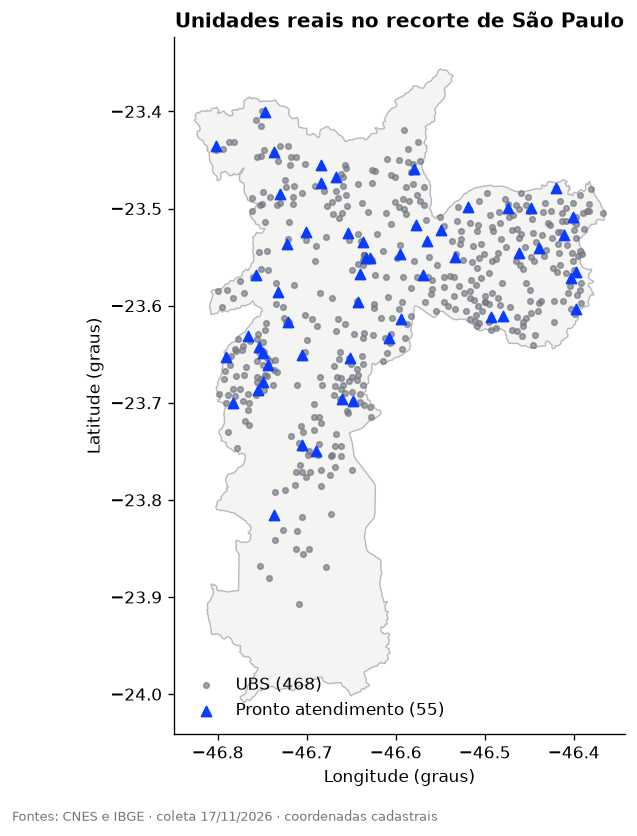

In [6]:
fig, ax = plt.subplots(figsize=(8.5,7))
for f in malha['features']:
    g=f['geometry']; polys=[g['coordinates']] if g['type']=='Polygon' else g['coordinates']
    for poly in polys:
        anel=np.asarray(poly[0]); ax.fill(anel[:,0],anel[:,1],color='#F4F4F2',zorder=0)
        ax.plot(anel[:,0],anel[:,1],color='#B6B8BE',lw=.8,zorder=1)
ax.scatter(ubs['lon'],ubs['lat'],s=11,c=CINZA,alpha=.65,label=f'UBS ({len(ubs)})')
ax.scatter(pa['lon'],pa['lat'],s=37,c=AZUL,marker='^',label=f'Pronto atendimento ({len(pa)})')
ax.set_aspect(1/np.cos(np.radians(-23.6)))
ax.set(xlabel='Longitude (graus)',ylabel='Latitude (graus)',title='Unidades reais no recorte de São Paulo')
ax.legend(frameon=False,loc='lower left')
fig.text(.12,.015,'Fontes: CNES e IBGE · coleta 17/11/2026 · coordenadas cadastrais',fontsize=8,color=CINZA)
fig.tight_layout(rect=[0,.035,1,1]); exibir_figura('mapa',fig)

In [7]:
q = resultado['d1_km'].quantile([.25,.5,.75,.9])
iqr = q.loc[.75]-q.loc[.25]
limite = q.loc[.75]+1.5*iqr
resultado['extremo_iqr'] = resultado['d1_km']>limite
estatisticas = pd.DataFrame({'medida':['Mínimo','P25','Mediana','Média','P75','P90','Máximo','IQR','Limite superior IQR'],
    'km':[resultado['d1_km'].min(),q.loc[.25],q.loc[.5],resultado['d1_km'].mean(),
          q.loc[.75],q.loc[.9],resultado['d1_km'].max(),iqr,limite]})
display(estatisticas.round(3))
print('UBS além do limite IQR:', int(resultado['extremo_iqr'].sum()))
print('Atualização cadastral SUS com mais de 180 dias:', int((sus['idade_dias']>180).sum()), 'de',len(sus))
print('Mediana de dias desde atualização (SUS):',float(sus['idade_dias'].median()))

,medida,km
0,Mínimo,0.000
1,P25,1.053
2,Mediana,1.856
3,Média,1.988
4,P75,2.678
5,P90,3.492
6,Máximo,10.559
7,IQR,1.625
8,Limite superior IQR,5.116


UBS além do limite IQR: 8
Atualização cadastral SUS com mais de 180 dias: 472 de 647
Mediana de dias desde atualização (SUS): 263.0


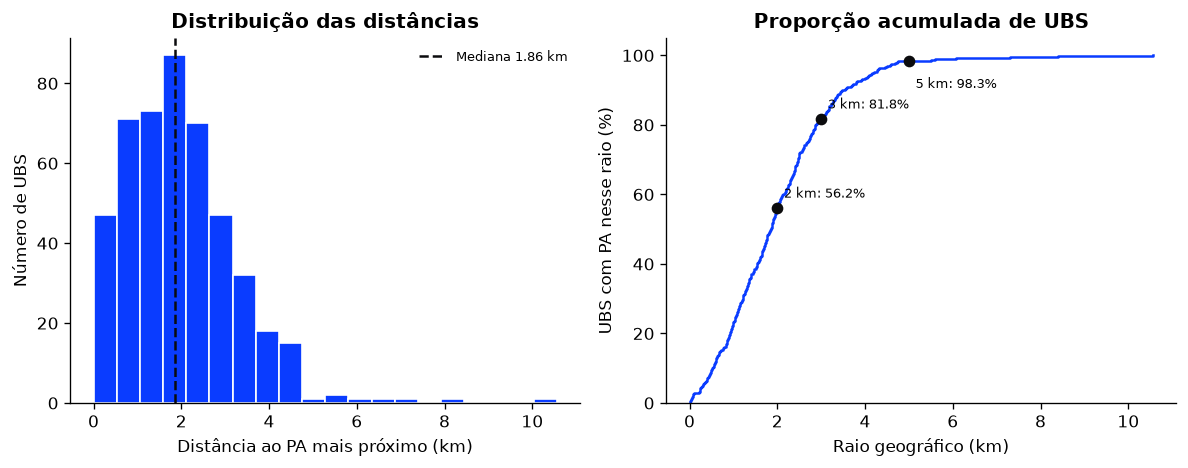

In [8]:
fig, axes = plt.subplots(1,2,figsize=(10,4))
axes[0].hist(resultado['d1_km'],bins=20,color=AZUL,edgecolor='white')
axes[0].axvline(q.loc[.5],color=TINTA,ls='--',label=f'Mediana {q.loc[.5]:.2f} km')
axes[0].set(xlabel='Distância ao PA mais próximo (km)',ylabel='Número de UBS',title='Distribuição das distâncias')
axes[0].legend(frameon=False,fontsize=8)
x=np.sort(resultado['d1_km']);y=100*np.arange(1,len(x)+1)/len(x)
axes[1].step(x,y,color=AZUL,where='post')
for raio in [2,3,5]:
    perc=100*np.mean(x<=raio)
    axes[1].plot(raio,perc,'o',color=TINTA)
    axes[1].annotate(f'{raio} km: {perc:.1f}%',(raio,perc),xytext=(4,-16 if raio==5 else 6),textcoords='offset points',fontsize=8)
axes[1].set(xlabel='Raio geográfico (km)',ylabel='UBS com PA nesse raio (%)',title='Proporção acumulada de UBS',ylim=(0,105))
fig.tight_layout();exibir_figura('distribuicao',fig)

## 6. Sensibilidade e decisão apoiada

Comparar "PA tipo 73" com "UPA no nome" evita tratar classes distintas como se fossem
iguais. A segunda definição é textual, não uma certificação de habilitação de UPA.
Ao mudar os destinos, mantemos as mesmas UBS para permitir comparação pareada.
O cenário de coordenadas não filtradas também muda as origens e, por isso, é apenas
um diagnóstico de sensibilidade ao tratamento geográfico.

In [9]:
pa_upa = pa[pa['nome'].str.contains(r'\bUPA\b',regex=True,na=False)].copy().reset_index(drop=True)
resultado_upa, D_upa = calcular_vizinhos(ubs, pa_upa)
ubs_sem_filtro = sus[(sus['tipo_codigo']==2) & nome_ubs.loc[sus.index] & sus['coord_valida']].copy().reset_index(drop=True)
pa_sem_filtro = sus[(sus['tipo_codigo']==73) & sus['coord_valida']].copy().reset_index(drop=True)
resultado_sem_filtro, _ = calcular_vizinhos(ubs_sem_filtro, pa_sem_filtro)
cenarios = [('Principal: PA tipo 73',resultado,len(pa)),
            ('Somente UPA no nome',resultado_upa,len(pa_upa)),
            ('Sem filtro de polígono',resultado_sem_filtro,len(pa_sem_filtro))]
sensibilidade = pd.DataFrame([{'cenário':nome, 'UBS':len(r), 'destinos':n,
    'mediana_km':r['d1_km'].median(), 'P90_km':r['d1_km'].quantile(.9),
    'máximo_km':r['d1_km'].max(), 'até_3km_pct':100*r['d1_km'].le(3).mean()}
    for nome,r,n in cenarios])
cobertura = pd.DataFrame([{'raio_km':raio, 'UBS_com_PA':int((resultado['d1_km']<=raio).sum()),
    'UBS_com_2_PA':int((resultado['d2_km']<=raio).sum()),
    'percentual_com_PA':100*(resultado['d1_km']<=raio).mean()} for raio in [2,3,5]])
display(sensibilidade.round(2))
display(cobertura.round(2))

,cenário,UBS,destinos,mediana_km,P90_km,máximo_km,até_3km_pct
0,Principal: PA tipo 73,468,55,1.86,3.49,10.56,81.84
1,Somente UPA no nome,468,35,2.38,5.24,10.56,65.81
2,Sem filtro de polígono,483,56,1.88,3.80,96.52,79.92


,raio_km,UBS_com_PA,UBS_com_2_PA,percentual_com_PA
0,2,263,76,56.20
1,3,383,212,81.84
2,5,460,418,98.29


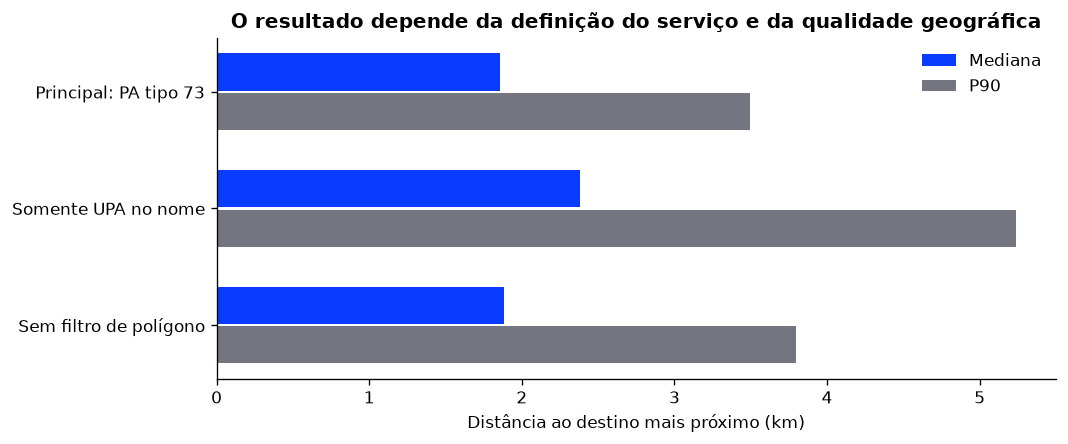

In [10]:
fig, ax = plt.subplots(figsize=(9,3.8))
pos=np.arange(3)
ax.barh(pos-.17,sensibilidade['mediana_km'],height=.32,color=AZUL,label='Mediana')
ax.barh(pos+.17,sensibilidade['P90_km'],height=.32,color=CINZA,label='P90')
ax.set_yticks(pos,sensibilidade['cenário']);ax.invert_yaxis()
ax.set(xlabel='Distância ao destino mais próximo (km)',title='O resultado depende da definição do serviço e da qualidade geográfica')
ax.legend(frameon=False);fig.tight_layout();exibir_figura('sensibilidade',fig)

In [11]:
# Lista para auditoria cadastral e territorial, ordenada pela distância calculada.
prioridades = resultado.sort_values(['d1_km','cnes'],ascending=[False,True]).head(10)
display(prioridades[['cnes','nome','pa_nome','d1_km','d2_km','pa_3km']].round(2).reset_index(drop=True))
print('Maior distância no recorte:', prioridades.iloc[0]['nome'])
print('PA mais próximo pelas coordenadas:', prioridades.iloc[0]['pa_nome'])
print('Distância calculada:', round(prioridades.iloc[0]['d1_km'],2), 'km')

,cnes,nome,pa_nome,d1_km,d2_km,pa_3km
0,6332471,UBS MARSILAC,UPA PARELHEIROS,10.56,17.58,0
1,6332498,UBS NOVA AMERICA,UPA PARELHEIROS,8.41,13.31,0
2,6018912,UBS JARDIM EMBURA,UPA PARELHEIROS,7.30,15.54,0
3,6090591,UBS CHACARA SANTO AMARO,UPA PARELHEIROS,6.47,7.45,0
4,6332439,UBS JARDIM DAS FONTES,UPA PARELHEIROS,6.06,14.60,0
5,6018939,UBS COLONIA,UPA PARELHEIROS,5.59,11.23,0
6,2789280,UBS VARGEM GRANDE,UPA PARELHEIROS,5.49,11.86,0
7,2787105,UBS HORIZONTE AZUL,AMA 24H PARQUE NOVO SANTO AMARO,5.21,7.11,0
8,4700449,UBS PARQUE DAS FLORES,PA MUN SAO MATEUS II,4.75,5.77,0
9,8147159,UBS HELENA MIGUEL REZEK,UPA III RIO PEQUENO,4.74,6.24,0


Maior distância no recorte: UBS MARSILAC
PA mais próximo pelas coordenadas: UPA PARELHEIROS
Distância calculada: 10.56 km


In [12]:
resumo = {
    'n_brutos':len(brutos), 'n_sus':len(sus), 'n_sus_dentro':len(sus_dentro),
    'n_sus_fora':len(sus_fora), 'n_ubs':len(ubs), 'n_pa':len(pa), 'n_upa_nome':len(pa_upa),
    'duplicados':duplicados, 'n_extremos':int(resultado['extremo_iqr'].sum()),
    'mediana_km':float(q.loc[.5]), 'p25_km':float(q.loc[.25]), 'p75_km':float(q.loc[.75]),
    'p90_km':float(q.loc[.9]), 'media_km':float(resultado['d1_km'].mean()),
    'max_km':float(resultado['d1_km'].max()), 'limite_iqr_km':float(limite),
    'idade_mediana':float(sus['idade_dias'].median()),
    'cadastros_180dias':int(sus['idade_dias'].gt(180).sum()),
    'sensibilidade':sensibilidade.to_dict('records'), 'cobertura':cobertura.to_dict('records'),
    'prioridades':prioridades[['cnes','nome','pa_nome','d1_km','d2_km','pa_3km']].to_dict('records'),
    'sus_fora':sus_fora[['cnes','nome','tipo_codigo','lat','lon']].to_dict('records'),
    'tipos':pd.crosstab(dados['tipo'],dados['sus']).reset_index().to_dict('records'),
    'cnes_sha256':hashlib.sha256(raw_cnes).hexdigest(),
    'ibge_sha256':hashlib.sha256(raw_ibge).hexdigest(),
    'versoes':{'python':platform.python_version(),'numpy':np.__version__,
               'pandas':pd.__version__,'matplotlib':matplotlib.__version__}}
ate3 = cobertura.loc[cobertura['raio_km']==3].iloc[0]
texto = f'''### Interpretação calculada nesta execução

O recorte principal contém **{len(ubs)} UBS** e **{len(pa)} serviços de pronto atendimento**.
A mediana da distância ao PA mais próximo é **{q.loc[.5]:.2f} km** e o P90 é
**{q.loc[.9]:.2f} km**. Há **{int(ate3['UBS_com_PA'])} UBS ({ate3['percentual_com_PA']:.1f}%)**
com pelo menos um PA a até 3 km pelas coordenadas.

Esses números descrevem a proximidade entre estabelecimentos selecionados; não medem
cobertura populacional nem acesso efetivo. A análise fornece uma lista verificável de
pontos para revisão cadastral e para planejar a integração do catálogo do FilaZero.
'''
display(Markdown(texto))
# Exportação opcional usada pelo autor do relatório; não é necessária ao notebook.
if os.environ.get('FILA_ZERO_ARTEFATOS'):
    Path(os.environ['FILA_ZERO_ARTEFATOS'],'resumo.json').write_text(json.dumps(resumo,ensure_ascii=False,indent=2),encoding='utf-8')

### Interpretação calculada nesta execução

O recorte principal contém **468 UBS** e **55 serviços de pronto atendimento**.
A mediana da distância ao PA mais próximo é **1.86 km** e o P90 é
**3.49 km**. Há **383 UBS (81.8%)**
com pelo menos um PA a até 3 km pelas coordenadas.

Esses números descrevem a proximidade entre estabelecimentos selecionados; não medem
cobertura populacional nem acesso efetivo. A análise fornece uma lista verificável de
pontos para revisão cadastral e para planejar a integração do catálogo do FilaZero.


## 7. Limitações, conclusões e uso no FilaZero

**Limitações.** O CNES é cadastro declaratório: atualização antiga não comprova que
uma unidade fechou e atualização recente não garante disponibilidade operacional.
Coordenadas dentro do polígono ainda podem estar erradas. O polígono da API IBGE é
simplificado; o filtro pode sinalizar unidades de fronteira. O filtro SUS é ambulatorial,
e as UBS foram delimitadas pelo nome; existem serviços de atenção básica fora desse
recorte. Serviços de municípios vizinhos, tipos 20/21 e hospitais não compõem o cálculo
de destinos, embora possam ser relevantes em uma análise de acesso mais abrangente.

Distância em grande círculo ignora ruas, barreiras, trânsito, transporte, horários,
especialidades e regulação. A unidade mais próxima não é necessariamente adequada.
A unidade de análise é o estabelecimento, com peso igual para cada UBS. Os resultados
não representam população coberta, capacidade dos serviços ou demanda assistencial.
As maiores distâncias indicam casos para investigação cadastral e territorial, sem
comprovar déficit de atendimento. As conclusões se referem ao extrato e aos filtros
documentados, não a toda a rede de saúde.

**Conclusão.** Dados reais permitem ampliar e auditar o catálogo e medir proximidade
geográfica com uma definição explícita dos tipos de serviço. O recorte mostra
heterogeneidade das distâncias e sensibilidade à qualidade das coordenadas e à
definição de PA/UPA. O resultado apoia curadoria e planejamento de integração.

**Aplicação proposta.** (1) revisar os CNES sinalizados em fonte municipal e na unidade;
(2) incorporar IDs e tipos oficiais ao catálogo; (3) apresentar origem e data do cadastro;
(4) usar os indicadores de proximidade para organizar a revisão territorial; (5) repetir
o procedimento em novas versões do CNES, preservando os extratos, critérios e hashes
para comparar a qualidade cadastral ao longo das atualizações.

**Resultado prático.** O notebook entrega um recorte reproduzível, um diagnóstico de
qualidade geográfica, indicadores de proximidade e uma lista verificável de registros
para revisão. Esses produtos sustentam a curadoria do catálogo do FilaZero.

**Entrega:** apenas este notebook e o relatório PDF; somente o líder deve postar os
dois arquivos. Nenhuma postagem foi realizada por este notebook.

### Referências técnicas e do projeto

- Ministério da Saúde. CNES / API de Dados Abertos. [Portal](https://dadosabertos.saude.gov.br/dataset/cnes-cadastro-nacional-de-estabelecimentos-de-saude),
  [tipos de unidade](https://apidadosabertos.saude.gov.br/cnes/tipounidades). Acesso: 17/11/2026.
- IBGE. Malhas municipais / API v3. [Página institucional](https://www.ibge.gov.br/geociencias/organizacao-do-territorio/malhas-territoriais/15774-malhas.html).
  Acesso: 17/11/2026.
- Equipe FilaZero. [Documento de Visão UPA Agora](https://github.com/Luqetaa/FilaZero/blob/4008bc625ce49e4927f6a81783441b55c9121e4d/Documento_de_Visao_UPA_Agora.pdf),
  v0.1, 13/11/2026, contexto de orientação e comparação de unidades; e [Guia de Identidade Visual](https://github.com/Luqetaa/FilaZero/blob/4008bc625ce49e4927f6a81783441b55c9121e4d/Fila_Zero_Design_Guidelines.md).
- NumPy. [Funções matemáticas](https://numpy.org/doc/stable/reference/routines.math.html).
- pandas. [Conversão de datas e tratamento de ausentes](https://pandas.pydata.org/docs/reference/api/pandas.to_datetime.html).
- Matplotlib. [Teste de ponto em polígono](https://matplotlib.org/stable/api/path_api.html#matplotlib.path.Path.contains_points).

### Atualizar a coleta (opcional)

O código abaixo documenta a aquisição completa. Ele só acessa a rede se a flag for
alterada para True. A nova coleta não substitui automaticamente o extrato analisado;
registre novo hash e refaça todos os resultados para publicar uma atualização.

In [13]:
def coletar_cnes_real():
    import urllib.request, urllib.parse, time
    registros, consultas = [], []
    for tipo in [2,73,5,7]:
        pagina, vistos = 0, set()
        while True:
            parametros = dict(codigo_municipio=355030, codigo_tipo_unidade=tipo,
                              status=1, limit=20, offset=pagina)
            url='https://apidadosabertos.saude.gov.br/cnes/estabelecimentos?'+urllib.parse.urlencode(parametros)
            for tentativa in range(4):
                try:
                    with urllib.request.urlopen(url,timeout=45) as resposta:
                        corpo=resposta.read()
                    lote=json.loads(corpo)['estabelecimentos'];break
                except Exception:
                    if tentativa==3: raise
                    time.sleep(tentativa+1)
            consultas.append({'url':url,'registros':len(lote),'sha256':hashlib.sha256(corpo).hexdigest()})
            ids={r['codigo_cnes'] for r in lote}
            assert len(ids)==len(lote) and not (ids & vistos)
            assert all(r['codigo_municipio']==355030 and r['codigo_tipo_unidade']==tipo for r in lote)
            vistos.update(ids);registros.extend(lote)
            if len(lote)<20: break
            pagina+=1
            assert pagina<200, 'Limite de segurança da paginação atingido'
    return pd.DataFrame(registros),pd.DataFrame(consultas)

ATUALIZAR_DADOS = False
if ATUALIZAR_DADOS:
    nova_coleta, novas_consultas = coletar_cnes_real()
    print('Nova coleta recebida; o extrato do estudo foi preservado:',len(nova_coleta))
else:
    print('Reprodução concluída com a base real incorporada, sem nova consulta à rede.')

Reprodução concluída com a base real incorporada, sem nova consulta à rede.
